# Policy vs Policy (Common Routes Only)

This section compares two policies only on `(start_idx, target_idx)` pairs that both completed successfully.

- `algo1` and `algo2` can be any policy ID, or `"dij"` to resolve the Dijkstra baseline folder.
- Success/completion is defined from `failed_error`.
- Duplicate OD pairs (if any) are collapsed to the fastest successful row per pair before comparison.
- Completion-time comparisons include box plot, mean bar chart, and histogram.
- Route-level plots use a consistent `route_index` after sorting by `(start_idx, target_idx)`.

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re

# --- User-editable algorithm selectors ---
# Set to any policy ID (e.g. "b3ef6da6") or "dij" for the Dijkstra baseline folder
algo1 = "dij"
algo2 = "964ad609"

# --- Helpers ---
def resolve_algo_dir(runs_root: Path, algo_hint: str) -> Path:
    algo_hint = algo_hint.strip().lower()
    candidates = [p for p in runs_root.iterdir() if p.is_dir()]

    exact = [p for p in candidates if p.name.lower() == algo_hint]
    if exact:
        return exact[0]

    fuzzy = [
        p for p in candidates
        if p.name.lower().startswith(algo_hint) or algo_hint in p.name.lower()
    ]
    if len(fuzzy) == 1:
        return fuzzy[0]
    if len(fuzzy) > 1:
        return sorted(fuzzy, key=lambda p: (len(p.name), p.name))[0]

    raise ValueError(f"No algorithm directory found under {runs_root} for hint: {algo_hint!r}")


def latest_test_csv(algo_dir: Path) -> Path:
    tests = [p for p in algo_dir.glob("test_*") if p.is_dir()]
    if not tests:
        raise ValueError(f"No test_* directories found in {algo_dir}")

    def test_index(path: Path):
        m = re.match(r"test_(\d+)$", path.name)
        return int(m.group(1)) if m else -1

    selected = sorted(tests, key=lambda p: (test_index(p), p.stat().st_mtime))[-1]
    csv_path = selected / "simulation_results.csv"
    if not csv_path.exists():
        raise ValueError(f"Missing simulation_results.csv in {selected}")
    return csv_path


def is_completed_from_failed_error(series: pd.Series) -> pd.Series:
    as_str = series.astype("string").str.strip().str.lower()
    return series.isna() | as_str.isin(["", "na", "nan", "none"])


# --- Inputs ---
runs_root = Path("../runs/trsp")
algo1_dir = resolve_algo_dir(runs_root, algo1)
algo2_dir = resolve_algo_dir(runs_root, algo2)

algo1_csv = latest_test_csv(algo1_dir)
algo2_csv = latest_test_csv(algo2_dir)

algo1_label = algo1_dir.name
algo2_label = algo2_dir.name

key_cols = ["start_idx", "target_idx"]
time_col = "total_time_taken"
path_col = "path_edges"
success_col = "failed_error"
required_cols = key_cols + [time_col, path_col, success_col]

# --- Load ---
df_algo1 = pd.read_csv(algo1_csv)
df_algo2 = pd.read_csv(algo2_csv)

for name, df in [(algo1_label, df_algo1), (algo2_label, df_algo2)]:
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{name} missing required columns: {missing}")

for df in [df_algo1, df_algo2]:
    df["start_idx"] = pd.to_numeric(df["start_idx"], errors="coerce").astype("Int64")
    df["target_idx"] = pd.to_numeric(df["target_idx"], errors="coerce").astype("Int64")
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")

print(f"Using files -> {algo1_label}: {algo1_csv}")
print(f"Using files -> {algo2_label}: {algo2_csv}")

# --- SUCCESS filtering ---
success_algo1_full = is_completed_from_failed_error(df_algo1[success_col]) & (df_algo1[time_col] > 0)
success_algo2_full = is_completed_from_failed_error(df_algo2[success_col]) & (df_algo2[time_col] > 0)

df_algo1_success = df_algo1.loc[success_algo1_full].copy()
df_algo2_success = df_algo2.loc[success_algo2_full].copy()

print(f"Successful rows -> {algo1_label}: {len(df_algo1_success)}/{len(df_algo1)}, "
      f"{algo2_label}: {len(df_algo2_success)}/{len(df_algo2)}")

# --- Deduplicate: keep the fastest row per (start_idx, target_idx) ---
# Duplicate OD pairs arise from eval restarts; keeping min-time is most conservative.
df_algo1_success = (df_algo1_success
                    .sort_values(time_col)
                    .drop_duplicates(subset=key_cols, keep="first")
                    .reset_index(drop=True))
df_algo2_success = (df_algo2_success
                    .sort_values(time_col)
                    .drop_duplicates(subset=key_cols, keep="first")
                    .reset_index(drop=True))

print(f"After dedup -> {algo1_label}: {len(df_algo1_success)}, {algo2_label}: {len(df_algo2_success)}")

# --- Intersect: keep only OD pairs both algorithms completed ---
pairs_algo1 = set(zip(df_algo1_success["start_idx"], df_algo1_success["target_idx"]))
pairs_algo2 = set(zip(df_algo2_success["start_idx"], df_algo2_success["target_idx"]))
common_pairs = pairs_algo1 & pairs_algo2

mask_algo1 = df_algo1_success.apply(lambda r: (r["start_idx"], r["target_idx"]) in common_pairs, axis=1)
mask_algo2 = df_algo2_success.apply(lambda r: (r["start_idx"], r["target_idx"]) in common_pairs, axis=1)

df_algo1_common = df_algo1_success.loc[mask_algo1].sort_values(key_cols).reset_index(drop=True)
df_algo2_common = df_algo2_success.loc[mask_algo2].sort_values(key_cols).reset_index(drop=True)

assert len(df_algo1_common) == len(df_algo2_common), \
    f"Row mismatch after dedup+intersect: {algo1_label}={len(df_algo1_common)} vs {algo2_label}={len(df_algo2_common)}"

same_keys = (df_algo1_common[key_cols].values == df_algo2_common[key_cols].values).all()
assert same_keys, "Route ordering mismatch after sorting common pairs."

# --- Same-path adjustment: if both took identical edges, credit both with min time ---
path1 = df_algo1_common[path_col].astype("string").fillna("").str.strip()
path2 = df_algo2_common[path_col].astype("string").fillna("").str.strip()
same_path_mask = path1 == path2

min_shared_time = np.minimum(df_algo1_common[time_col].values, df_algo2_common[time_col].values)
df_algo1_common.loc[same_path_mask, time_col] = min_shared_time[same_path_mask.values]
df_algo2_common.loc[same_path_mask, time_col] = min_shared_time[same_path_mask.values]

print(f"Same-path rows adjusted to shared min time: {int(same_path_mask.sum())}")

df_algo1_common["route_index"] = np.arange(len(df_algo1_common))
df_algo2_common["route_index"] = np.arange(len(df_algo2_common))

route_key = (df_algo1_common["start_idx"].astype(str) + "->" + df_algo1_common["target_idx"].astype(str))
df_algo1_common["route_key"] = route_key
df_algo2_common["route_key"] = route_key

# --- Summary ---
summary = pd.DataFrame({
    "algorithm": [algo1_label, algo2_label],
    "completed_routes_in_full_df": [int(success_algo1_full.sum()), int(success_algo2_full.sum())],
    "total_routes_in_full_df": [len(df_algo1), len(df_algo2)],
    "routes_used_for_comparison": [len(df_algo1_common), len(df_algo2_common)],
})
summary["success_rate_pct_full_df"] = (
    100 * summary["completed_routes_in_full_df"] / summary["total_routes_in_full_df"]
)

print(f"Common successful OD pairs: {len(common_pairs)}")
print("\nSuccess summary:")
display(summary)

aligned = pd.DataFrame({
    "route_index": df_algo1_common["route_index"],
    "start_idx":   df_algo1_common["start_idx"],
    "target_idx":  df_algo1_common["target_idx"],
    "route_key":   df_algo1_common["route_key"],
    f"{algo1_label}_time":  df_algo1_common[time_col],
    f"{algo2_label}_time":  df_algo2_common[time_col],
    f"{algo1_label}_edges": df_algo1_common[path_col],
    f"{algo2_label}_edges": df_algo2_common[path_col],
})
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"
aligned[diff_col] = aligned[f"{algo2_label}_time"] - aligned[f"{algo1_label}_time"]

time_summary = pd.DataFrame({
    "algorithm":   [algo1_label, algo2_label],
    "mean_time":   [df_algo1_common[time_col].mean(),   df_algo2_common[time_col].mean()],
    "median_time": [df_algo1_common[time_col].median(), df_algo2_common[time_col].median()],
    "min_time":    [df_algo1_common[time_col].min(),    df_algo2_common[time_col].min()],
    "max_time":    [df_algo1_common[time_col].max(),    df_algo2_common[time_col].max()],
})

print("\nTime summary (successful common OD routes, same-path adjusted):")
display(time_summary)
display(aligned.head(10))

Using files -> dijkstra: ../runs/trsp/dijkstra/test_58/simulation_results.csv
Using files -> 964ad609: ../runs/trsp/964ad609/test_1/simulation_results.csv
Successful rows -> dijkstra: 98/100, 964ad609: 95/100
After dedup -> dijkstra: 91, 964ad609: 88
Same-path rows adjusted to shared min time: 64
Common successful OD pairs: 87

Success summary:


,algorithm,completed_routes_in_full_df,total_routes_in_full_df,routes_used_for_comparison,success_rate_pct_full_df
0,dijkstra,98,100,87,98.0
1,964ad609,95,100,87,95.0



Time summary (successful common OD routes, same-path adjusted):


,algorithm,mean_time,median_time,min_time,max_time
0,dijkstra,129.241379,125.0,1.0,362.0
1,964ad609,128.793103,125.0,1.0,397.0


,route_index,start_idx,target_idx,route_key,dijkstra_time,964ad609_time,dijkstra_edges,964ad609_edges,time_diff_964ad609_minus_dijkstra
0,0,0,3,0->3,128.0,128.0,-E3;161118998_to_161035628;161035628_to_161119012,-E3;161118998_to_161035628;161035628_to_161119012,0.0
1,1,0,18,0->18,180.0,180.0,-E3;161118998_to_161035628;161035628_to_161119...,-E3;161118998_to_161035628;161035628_to_161119...,0.0
2,2,0,24,0->24,187.0,187.0,-E3;161118998_to_161035628;161035628_to_161119...,-E3;161118998_to_161035628;161035628_to_161119...,0.0
3,3,0,25,0->25,88.0,167.0,-E2;161167680_to_cluster_161156577_161156691,-E4;E1;cluster_10781666531_10781666539_1454602...,79.0
4,4,1,0,1->0,84.0,84.0,161035628_to_161118998;E3,161035628_to_161118998;E3,0.0
5,5,1,22,1->22,45.0,45.0,161035628_to_cluster_161035662_161035665,161035628_to_cluster_161035662_161035665,0.0
6,6,1,24,1->24,115.0,111.0,161035628_to_161119012;161119012_to_1756935507...,161035628_to_cluster_161035662_161035665;clust...,-4.0
7,7,2,1,2->1,20.0,20.0,161118998_to_161035628,161118998_to_161035628,0.0
8,8,2,8,2->8,1.0,1.0,161118998_to_161035628;161035628_to_161119012;...,161118998_to_161035628;161035628_to_161119012;...,0.0
9,9,2,13,2->13,1.0,272.0,E3;-E2;161167680_to_161132174;161132174_to_161...,E3;-E4;E1;cluster_10781666531_10781666539_1454...,271.0


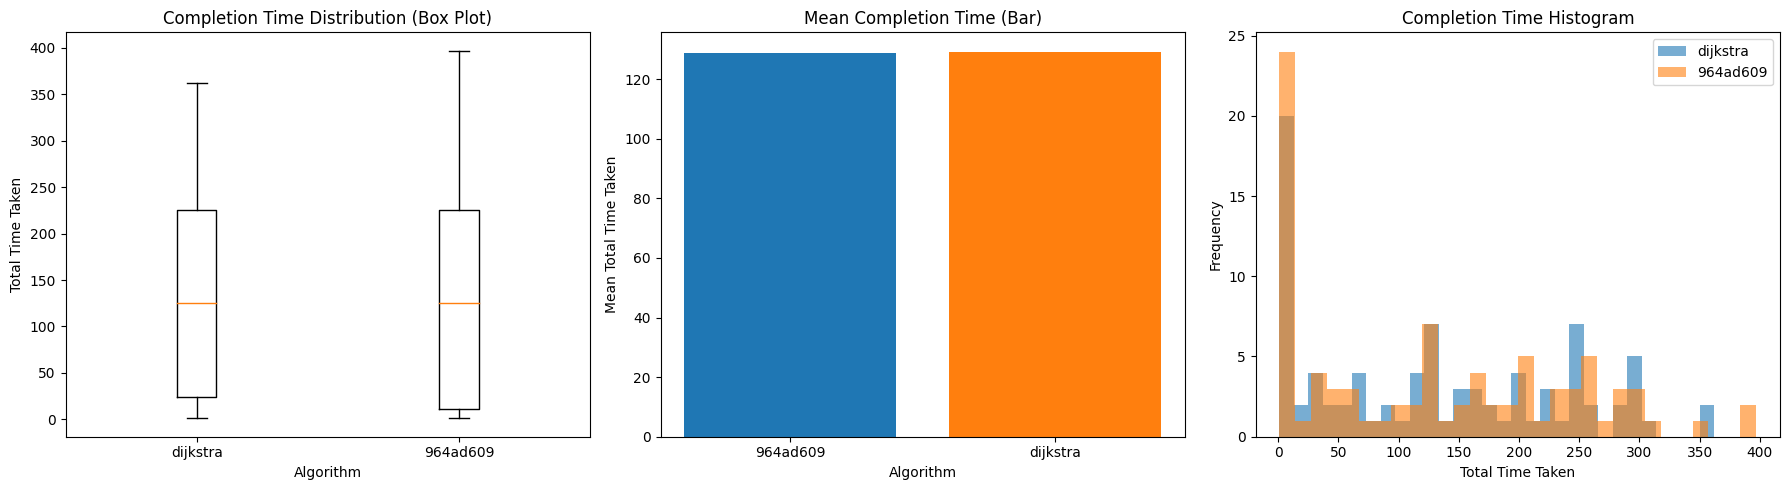

In [44]:
# --- Time comparison plots: box, mean bar, histogram ---
plot_df = pd.concat(
    [
        pd.DataFrame({"algorithm": algo1_label, "total_time_taken": df_algo1_common["total_time_taken"]}),
        pd.DataFrame({"algorithm": algo2_label, "total_time_taken": df_algo2_common["total_time_taken"]}),
    ],
    ignore_index=True,
)

means = (
    plot_df.groupby("algorithm", as_index=False)["total_time_taken"]
    .mean()
    .rename(columns={"total_time_taken": "mean_total_time_taken"})
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot
algorithms = [algo1_label, algo2_label]
box_data = [
    plot_df.loc[plot_df["algorithm"] == algo, "total_time_taken"].dropna().values
    for algo in algorithms
]
axes[0].boxplot(box_data, labels=algorithms)
axes[0].set_title("Completion Time Distribution (Box Plot)")
axes[0].set_xlabel("Algorithm")
axes[0].set_ylabel("Total Time Taken")

# Mean bar chart
axes[1].bar(means["algorithm"], means["mean_total_time_taken"], color=["#1f77b4", "#ff7f0e"])
axes[1].set_title("Mean Completion Time (Bar)")
axes[1].set_xlabel("Algorithm")
axes[1].set_ylabel("Mean Total Time Taken")

# Histogram overlay
bins = 30
axes[2].hist(df_algo1_common["total_time_taken"], bins=bins, alpha=0.6, label=algo1_label)
axes[2].hist(df_algo2_common["total_time_taken"], bins=bins, alpha=0.6, label=algo2_label)
axes[2].set_title("Completion Time Histogram")
axes[2].set_xlabel("Total Time Taken")
axes[2].set_ylabel("Frequency")
axes[2].legend()

plt.tight_layout()
plt.show()

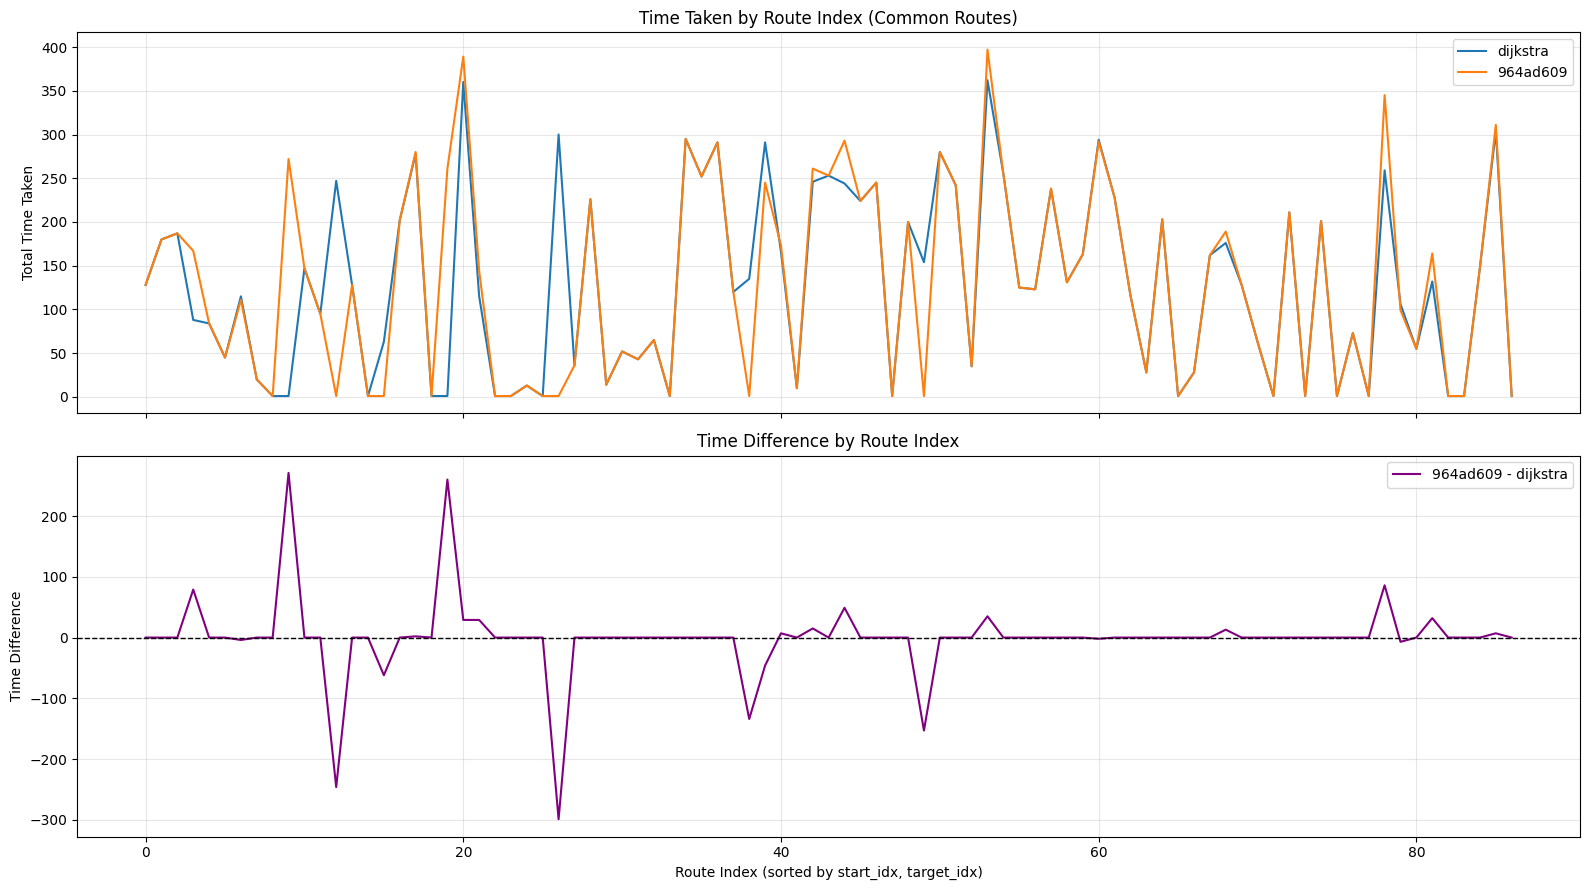

Mean time difference (964ad609 - dijkstra): -0.4482758620689655
Routes where 964ad609 is faster (diff < 0): 9
Routes where dijkstra is faster (diff > 0): 14
Routes with equal time: 64


In [45]:
# --- Route index plots: raw times and time difference ---
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

time_col_algo1 = f"{algo1_label}_time"
time_col_algo2 = f"{algo2_label}_time"
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"

axes[0].plot(aligned["route_index"], aligned[time_col_algo1], label=algo1_label, linewidth=1.5)
axes[0].plot(aligned["route_index"], aligned[time_col_algo2], label=algo2_label, linewidth=1.5)
axes[0].set_title("Time Taken by Route Index (Common Routes)")
axes[0].set_ylabel("Total Time Taken")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    aligned["route_index"],
    aligned[diff_col],
    color="purple",
    linewidth=1.5,
    label=f"{algo2_label} - {algo1_label}",
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Time Difference by Route Index")
axes[1].set_xlabel("Route Index (sorted by start_idx, target_idx)")
axes[1].set_ylabel("Time Difference")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean time difference ({algo2_label} - {algo1_label}):", aligned[diff_col].mean())
print(f"Routes where {algo2_label} is faster (diff < 0):", (aligned[diff_col] < 0).sum())
print(f"Routes where {algo1_label} is faster (diff > 0):", (aligned[diff_col] > 0).sum())
print("Routes with equal time:", (aligned[diff_col] == 0).sum())

Top 10 BEST routes for 964ad609 vs dijkstra (most negative diff):


,route_index,route_key,dijkstra_time,964ad609_time,time_diff_964ad609_minus_dijkstra
26,26,7->25,300.0,1.0,-299.0
12,12,2->20,247.0,1.0,-246.0
49,49,17->2,154.0,1.0,-153.0
38,38,11->6,135.0,1.0,-134.0
15,15,3->7,63.0,1.0,-62.0
39,39,11->19,291.0,245.0,-46.0
79,79,24->17,106.0,99.0,-7.0
6,6,1->24,115.0,111.0,-4.0
60,60,20->3,294.0,292.0,-2.0
0,0,0->3,128.0,128.0,0.0


Top 10 WORST routes for 964ad609 vs dijkstra (most positive diff):


,route_index,route_key,dijkstra_time,964ad609_time,time_diff_964ad609_minus_dijkstra
9,9,2->13,1.0,272.0,271.0
19,19,4->7,1.0,261.0,260.0
78,78,24->14,259.0,345.0,86.0
3,3,0->25,88.0,167.0,79.0
44,44,13->7,244.0,293.0,49.0
53,53,18->6,362.0,397.0,35.0
81,81,25->26,132.0,164.0,32.0
20,20,4->24,360.0,389.0,29.0
21,21,5->12,115.0,144.0,29.0
42,42,13->1,246.0,261.0,15.0


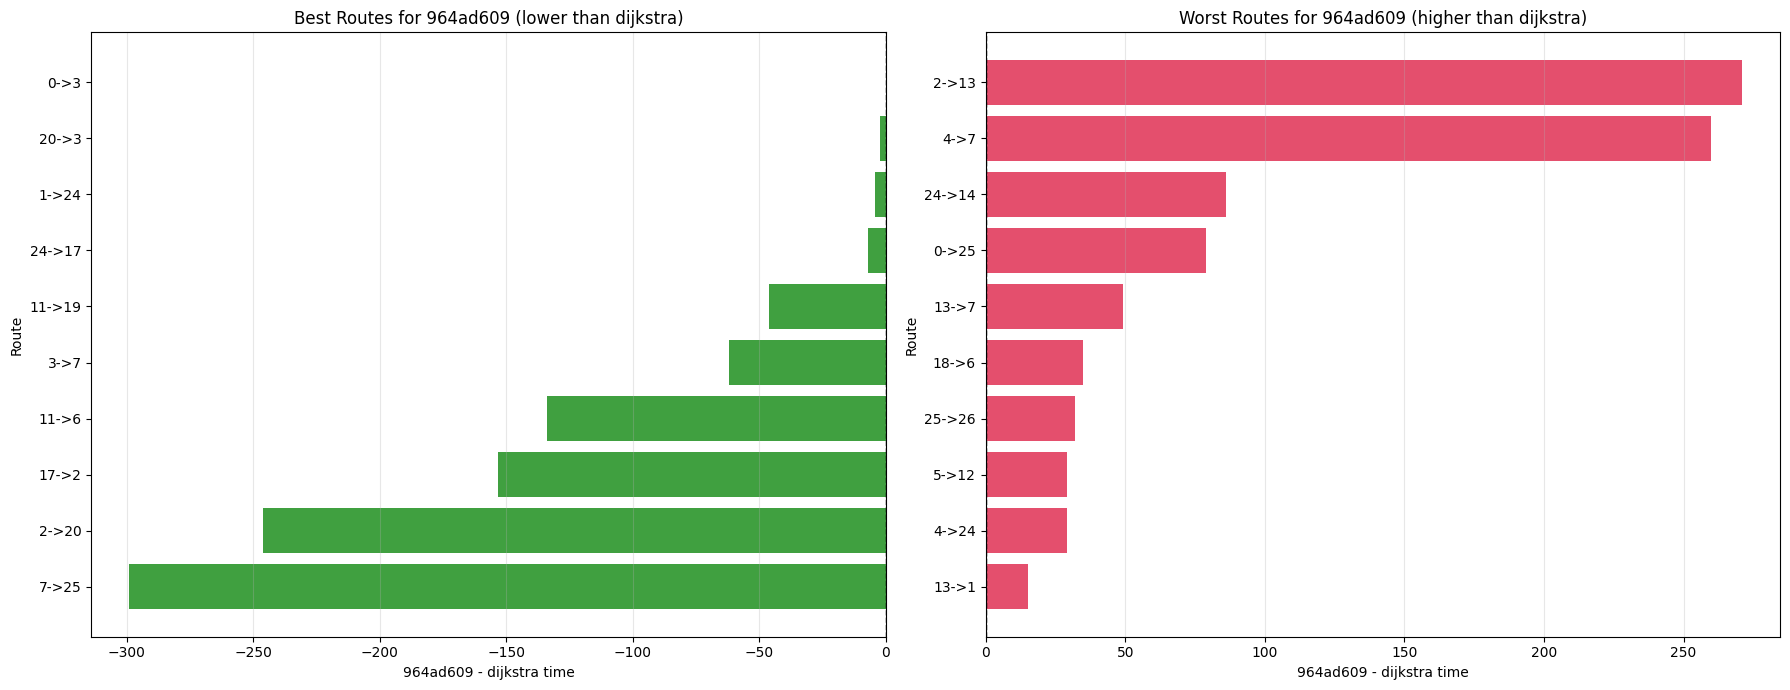

In [46]:
# --- Best and worst routes between the two algorithms ---
# diff_col is defined as: algo2_time - algo1_time
#   negative -> algo2 faster, positive -> algo1 faster

top_k = 10

time_col_algo1 = f"{algo1_label}_time"
time_col_algo2 = f"{algo2_label}_time"
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"

best_for_algo2 = aligned.nsmallest(top_k, diff_col).copy()
worst_for_algo2 = aligned.nlargest(top_k, diff_col).copy()

show_cols = ["route_index", "route_key", time_col_algo1, time_col_algo2, diff_col]

print(f"Top {top_k} BEST routes for {algo2_label} vs {algo1_label} (most negative diff):")
display(best_for_algo2[show_cols])

print(f"Top {top_k} WORST routes for {algo2_label} vs {algo1_label} (most positive diff):")
display(worst_for_algo2[show_cols])

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=False)

left_df = best_for_algo2.sort_values(diff_col, ascending=True)
right_df = worst_for_algo2.sort_values(diff_col, ascending=True)

axes[0].barh(left_df["route_key"], left_df[diff_col], color="green", alpha=0.75)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title(f"Best Routes for {algo2_label} (lower than {algo1_label})")
axes[0].set_xlabel(f"{algo2_label} - {algo1_label} time")
axes[0].set_ylabel("Route")
axes[0].grid(axis="x", alpha=0.3)

axes[1].barh(right_df["route_key"], right_df[diff_col], color="crimson", alpha=0.75)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title(f"Worst Routes for {algo2_label} (higher than {algo1_label})")
axes[1].set_xlabel(f"{algo2_label} - {algo1_label} time")
axes[1].set_ylabel("Route")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

---
## Highlight Routes — Where Each Policy Shines

For the top-N routes where `algo2` wins by the largest margin and where `algo1` wins by the largest margin, draw both paths on the road network. Solid lines are the actual edge sequences from `path_edges`. Routes that differ visually reveal the detour strategies learned by the RL policy.

Network: ../data/ames/ames_campus_final.net.xml
Nodes: 28   Edges: 80
  dijkstra_edges: sample=['-E3', '161118998_to_161035628', '161035628_to_161119012', '161119012_to_1756935507']  matched=['-E3', '161118998_to_161035628', '161035628_to_161119012', '161119012_to_1756935507']
  964ad609_edges: sample=['-E3', '161118998_to_161035628', '161035628_to_161119012', '161119012_to_1756935507']  matched=['-E3', '161118998_to_161035628', '161035628_to_161119012', '161119012_to_1756935507']


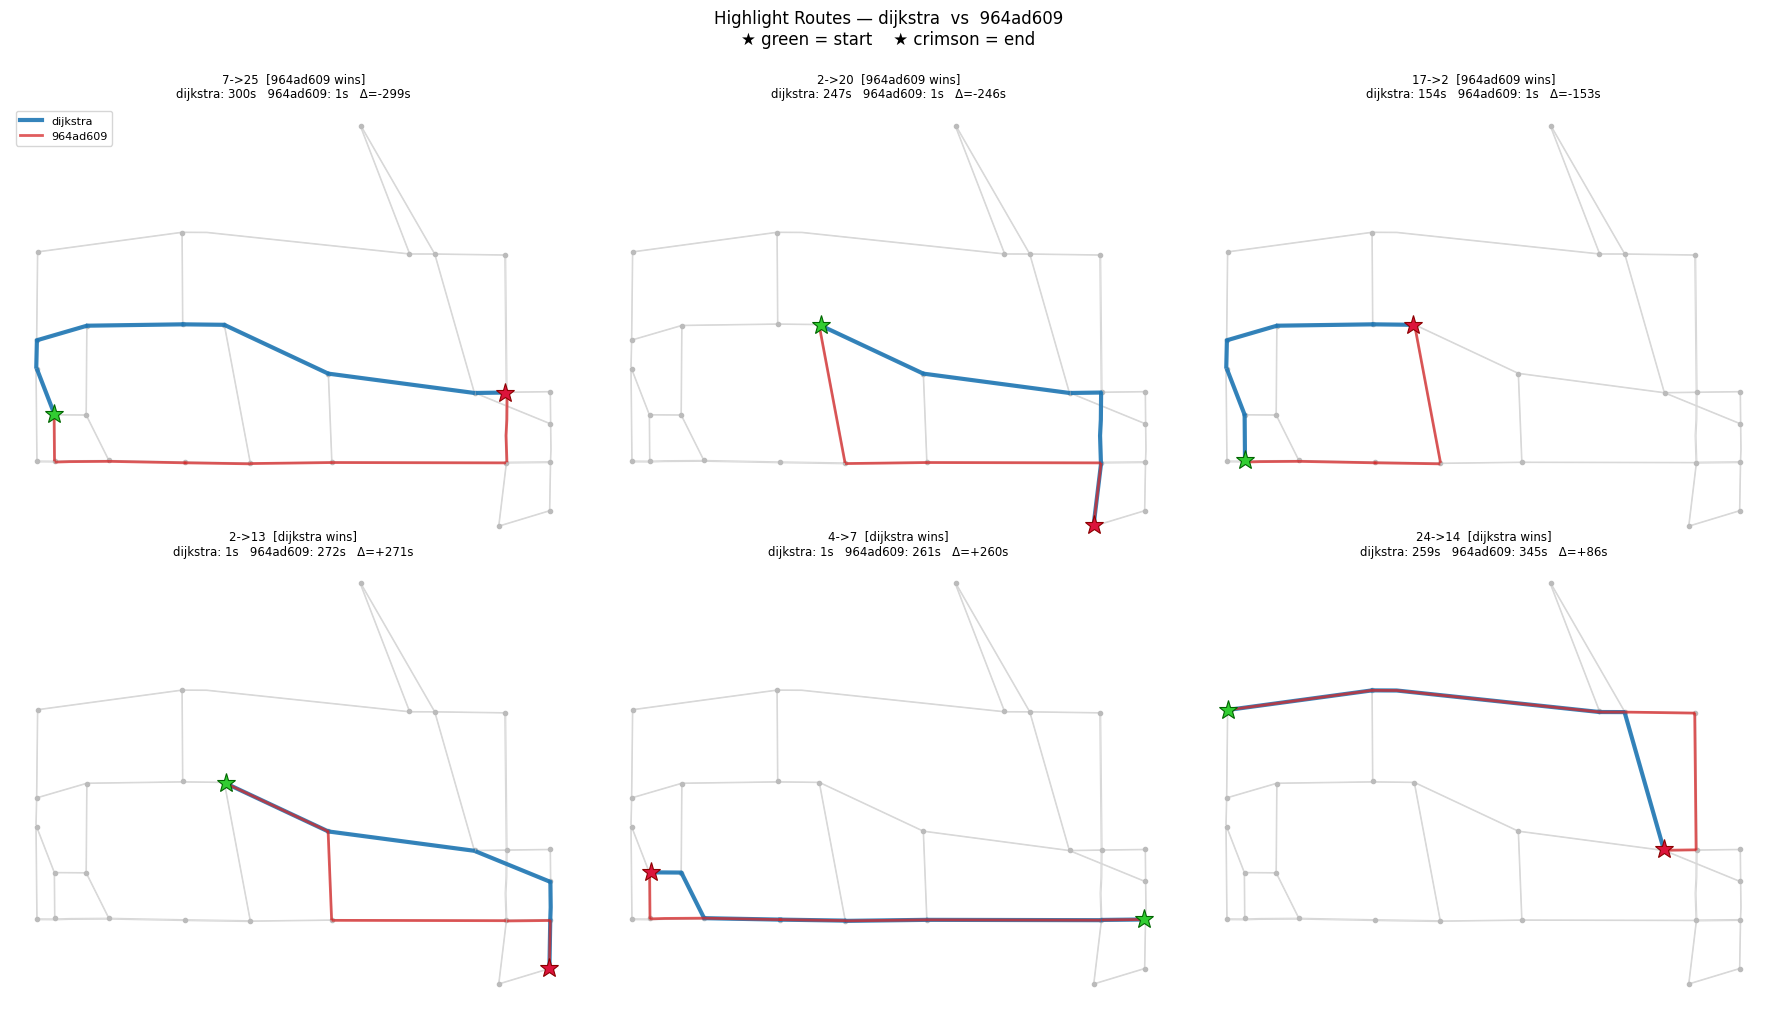

In [47]:
import sumolib
import yaml as _yaml

# --- Load network: prefer the test-level config (always exists) over the root config ---
# algo1_dir/config.yaml may not exist (e.g. dijkstra dir has no root-level config.yaml)
_cfg_candidates = [
    algo1_csv.parent / "config.yaml",   # test_N/config.yaml for algo1  ← most reliable
    algo2_csv.parent / "config.yaml",   # test_N/config.yaml for algo2
    algo1_dir / "config.yaml",          # root config (exists for trained-policy dirs)
    algo2_dir / "config.yaml",
]
_test_cfg = next((p for p in _cfg_candidates if p.exists()), None)
if _test_cfg is None:
    raise FileNotFoundError("Cannot find a config.yaml to determine net_path")

with open(_test_cfg) as _f:
    _cfg = _yaml.safe_load(_f)

_net_xml = Path("..") / _cfg["net"]["net_path"].replace(".sumocfg", ".net.xml")
print(f"Network: {_net_xml}")

_net = sumolib.net.readNet(str(_net_xml), withPedestrianConnections=False)

# --- Build maps ---
# edge_shape[eid]   → list of (x, y) shape points  (used for route drawing)
# node_pos[node_id] → (x, y) centroid
# sorted_node_ids   → same sorted order as the TRSP env's node2idx
edge_shape = {}
node_pos   = {}

for _edge in _net.getEdges():
    _eid = _edge.getID()
    if _eid.startswith(":"):
        continue
    _shape = _edge.getShape()
    if _shape:
        edge_shape[_eid] = _shape
    for _nd in (_edge.getFromNode(), _edge.getToNode()):
        _nid = _nd.getID()
        if _nid not in node_pos:
            _s = _nd.getShape()
            if _s:
                node_pos[_nid] = (
                    sum(p[0] for p in _s) / len(_s),
                    sum(p[1] for p in _s) / len(_s),
                )

# node index → (x, y), matching the env's sorted-node ordering
sorted_node_ids  = sorted(node_pos.keys())
node_idx_to_pos  = {i: node_pos[nid] for i, nid in enumerate(sorted_node_ids)}

print(f"Nodes: {len(node_pos)}   Edges: {len(edge_shape)}")

# --- Debug: verify that edge IDs in the eval CSVs match sumolib ---
for _col in (f"{algo1_label}_edges", f"{algo2_label}_edges"):
    if _col in aligned.columns:
        _notnull = aligned[_col].dropna()
        _sample_str = str(_notnull.iloc[1]) if len(_notnull) > 1 else ""
        _sample_ids = [e.strip() for e in _sample_str.split(";") if e.strip()][:4]
        _hits = [e for e in _sample_ids if e in edge_shape]
        print(f"  {_col}: sample={_sample_ids}  matched={_hits}")

# ------------------------------------------------------------------ helpers

def _parse_edges(edge_str):
    s = str(edge_str).strip().lower()
    if not s or s in ("nan", "-1", ""):
        return []
    return [e.strip() for e in str(edge_str).split(";") if e.strip()]

def _draw_network_bg(ax):
    for _eid, _shp in edge_shape.items():
        ax.plot([p[0] for p in _shp], [p[1] for p in _shp],
                color="#d8d8d8", lw=0.8, zorder=1)
    for _nid, (_x, _y) in node_pos.items():
        ax.plot(_x, _y, "o", color="#bbbbbb", ms=3, zorder=2)

def _draw_route_edges(ax, edge_list, color, lw=2.8, alpha=0.9, zorder=4, label=None):
    """Draw each edge in edge_list using its sumolib shape. Returns True if anything was drawn."""
    first = True
    for eid in edge_list:
        if eid in edge_shape:
            shp = edge_shape[eid]
            ax.plot([p[0] for p in shp], [p[1] for p in shp],
                    color=color, lw=lw, alpha=alpha, zorder=zorder,
                    label=label if first else None)
            first = False
    return not first   # True iff at least one edge was drawn

def _mark_endpoints(ax, edge_list, start_idx, end_idx):
    """Mark start ★ (green) and end ★ (crimson); fall back to node-index position."""
    # Start
    if edge_list and edge_list[0] in edge_shape:
        s = edge_shape[edge_list[0]][0]
    elif start_idx in node_idx_to_pos:
        s = node_idx_to_pos[start_idx]
    else:
        s = None
    if s:
        ax.plot(s[0], s[1], "*", color="limegreen", ms=14, zorder=7,
                markeredgecolor="darkgreen", mew=0.8)

    # End
    if edge_list and edge_list[-1] in edge_shape:
        e = edge_shape[edge_list[-1]][-1]
    elif end_idx in node_idx_to_pos:
        e = node_idx_to_pos[end_idx]
    else:
        e = None
    if e:
        ax.plot(e[0], e[1], "*", color="crimson", ms=14, zorder=7,
                markeredgecolor="darkred", mew=0.8)

# ------------------------------------------------------------------ select highlight rows

N = 3
highlight_rows = pd.concat([
    aligned.nsmallest(N, diff_col),   # algo2 wins by most
    aligned.nlargest(N, diff_col),    # algo1 wins by most
], ignore_index=True)

row_labels = [f"{algo2_label} wins"] * N + [f"{algo1_label} wins"] * N
COLORS     = {algo1_label: "#1f77b4", algo2_label: "#d62728"}

# ------------------------------------------------------------------ plot

fig, axes = plt.subplots(2, N, figsize=(6 * N, 10))
fig.suptitle(
    f"Highlight Routes — {algo1_label}  vs  {algo2_label}\n"
    "★ green = start    ★ crimson = end",
    fontsize=12, y=1.01,
)

for i, (_, row) in enumerate(highlight_rows.iterrows()):
    r, c = divmod(i, N)
    ax   = axes[r][c]

    edges1 = _parse_edges(row.get(f"{algo1_label}_edges", ""))
    edges2 = _parse_edges(row.get(f"{algo2_label}_edges", ""))
    s_idx  = int(row["start_idx"])
    t_idx  = int(row["target_idx"])

    _draw_network_bg(ax)
    drawn1 = _draw_route_edges(ax, edges1, COLORS[algo1_label], lw=3.0, zorder=4, label=algo1_label)
    drawn2 = _draw_route_edges(ax, edges2, COLORS[algo2_label], lw=2.0, alpha=0.75, zorder=5, label=algo2_label)

    _mark_endpoints(ax, edges1 if drawn1 else edges2, s_idx, t_idx)

    t1   = row[f"{algo1_label}_time"]
    t2   = row[f"{algo2_label}_time"]
    diff = row[diff_col]
    ax.set_title(
        f"{row['route_key']}  [{row_labels[i]}]\n"
        f"{algo1_label}: {t1:.0f}s   {algo2_label}: {t2:.0f}s   Δ={diff:+.0f}s",
        fontsize=8.5,
    )
    ax.set_aspect("equal")
    ax.axis("off")
    if i == 0:
        ax.legend(fontsize=8, loc="upper left", framealpha=0.8)

plt.tight_layout()
plt.show()

---
# Aggregated Results — All Policies

Scans every `runs/trsp/*/test_N/` folder, infers `(network, traffic)` from the test config, and writes one row per `(network, traffic, model)` combination to `results/trsp_results.csv`.

For dijkstra, which has multiple test folders covering different configurations, the highest-numbered test is used when the same `(network, traffic)` appears more than once. Results can then be compared across algorithms on the same network and traffic condition.

In [48]:
import os
import re as _re
import yaml
import pandas as pd
import numpy as np

TRSP_DIR = '../runs/trsp'

def infer_network_id(net_path):
    if 'rand_grid_road' in net_path: return 'N2'
    if 'grid_road'      in net_path: return 'N1'
    if 'ames'           in net_path: return 'N3'
    return 'UNKNOWN'

def infer_traffic_id(traffic_cfg):
    """Return a short traffic label: T1/T2/… for PSL slots, SVC-<tag> for SVC."""
    if traffic_cfg is None:
        return 'T0'
    model = traffic_cfg.get('model', 'psl')
    if model == 'svc':
        route_file = traffic_cfg.get('route_file', '')
        # extract the immediate parent directory name, e.g. "svc_123"
        tag = os.path.basename(os.path.dirname(route_file))
        if not tag:
            tag = 'svc'
        return f'SVC-{tag}'
    K = traffic_cfg.get('K', 1)
    return {1: 'T1', 2: 'T2', 3: 'T3', 4: 'T4'}.get(int(K), f'T{int(K)}')

def compute_stats(csv_path):
    df = pd.read_csv(csv_path)
    df['total_time_taken'] = pd.to_numeric(df['total_time_taken'], errors='coerce')
    is_ok = df['failed_error'].isna() | \
            df['failed_error'].astype(str).str.strip().str.upper().eq('NA')
    success = df[is_ok & (df['total_time_taken'] > 0)]
    if success.empty:
        return None
    t = success['total_time_taken']
    return dict(
        makespan_mean=round(t.mean(), 2),
        makespan_med=round(t.median(), 2),
        makespan_min=round(t.min(), 2),
        makespan_max=round(t.max(), 2),
        success_rate=round(len(success) / len(df), 4),
    )

# Scan all test_N dirs; for each (network_id, traffic_id, model) keep the highest-numbered test
best = {}   # (network_id, traffic_id, model) -> (test_num, csv_path, algo)

for entry in sorted(os.listdir(TRSP_DIR)):
    policy_path = os.path.join(TRSP_DIR, entry)
    if not os.path.isdir(policy_path):
        continue
    test_names = sorted(
        [d for d in os.listdir(policy_path) if d.startswith('test_')
         and os.path.isdir(os.path.join(policy_path, d))],
        key=lambda x: int(x.split('_')[1])
    )
    for test_name in test_names:
        test_num = int(test_name.split('_')[1])
        cfg_p = os.path.join(policy_path, test_name, 'config.yaml')
        csv_p = os.path.join(policy_path, test_name, 'simulation_results.csv')
        if not (os.path.exists(cfg_p) and os.path.exists(csv_p)):
            continue
        with open(cfg_p) as f:
            cfg = yaml.safe_load(f)
        algo  = cfg['agent']['algo']
        model = 'dijkstra' if algo == 'dijkstra' else cfg['agent'].get('policy', entry)
        traffic_cfg = cfg.get('traffic')
        key   = (infer_network_id(cfg['net']['net_path']),
                 infer_traffic_id(traffic_cfg),
                 model)
        if key not in best or test_num > best[key][0]:
            best[key] = (test_num, csv_p, algo)

rows = []
for (nid, tid, model), (_, csv_p, algo) in sorted(best.items()):
    stats = compute_stats(csv_p)
    if stats is None:
        continue
    rows.append({'network': nid, 'traffic': tid, 'model': model, 'algo': algo, **stats})

results_df = pd.DataFrame(rows, columns=[
    'network', 'traffic', 'model', 'algo',
    'makespan_mean', 'makespan_med', 'makespan_min', 'makespan_max', 'success_rate'
])
os.makedirs('../results', exist_ok=True)
results_df.to_csv('../results/trsp_results.csv', index=False)
print(f"Wrote {len(results_df)} rows → results/trsp_results.csv")
results_df

Wrote 66 rows → results/trsp_results.csv


,network,traffic,model,algo,makespan_mean,makespan_med,makespan_min,makespan_max,success_rate
0,N1,SVC-svc_123,b3ef6da6,dqn_svc,253.56,110.0,1.0,3537.0,0.96
1,N1,SVC-svc_123,dijkstra,dijkstra,378.04,142.0,1.0,3089.0,0.94
2,N1,T1,5b6c4910,dqn,181.56,171.5,37.0,482.0,0.98
3,N1,T1,5dd13f39,ppo,147.30,152.0,73.0,271.0,0.10
4,N1,T1,6ca77d6d,a2c,130.08,122.0,73.0,224.0,0.12
...,...,...,...,...,...,...,...,...,...
61,N3,T4,41cc3199,a2c,70.71,54.5,8.0,153.0,0.14
62,N3,T4,aa120033,dqn,152.26,150.0,6.0,375.0,0.94
63,N3,T4,b302b5d4,ppo,100.00,112.5,8.0,181.0,0.08
64,N3,T4,be5dbb1c,sarsa,163.25,152.0,6.0,541.0,0.77


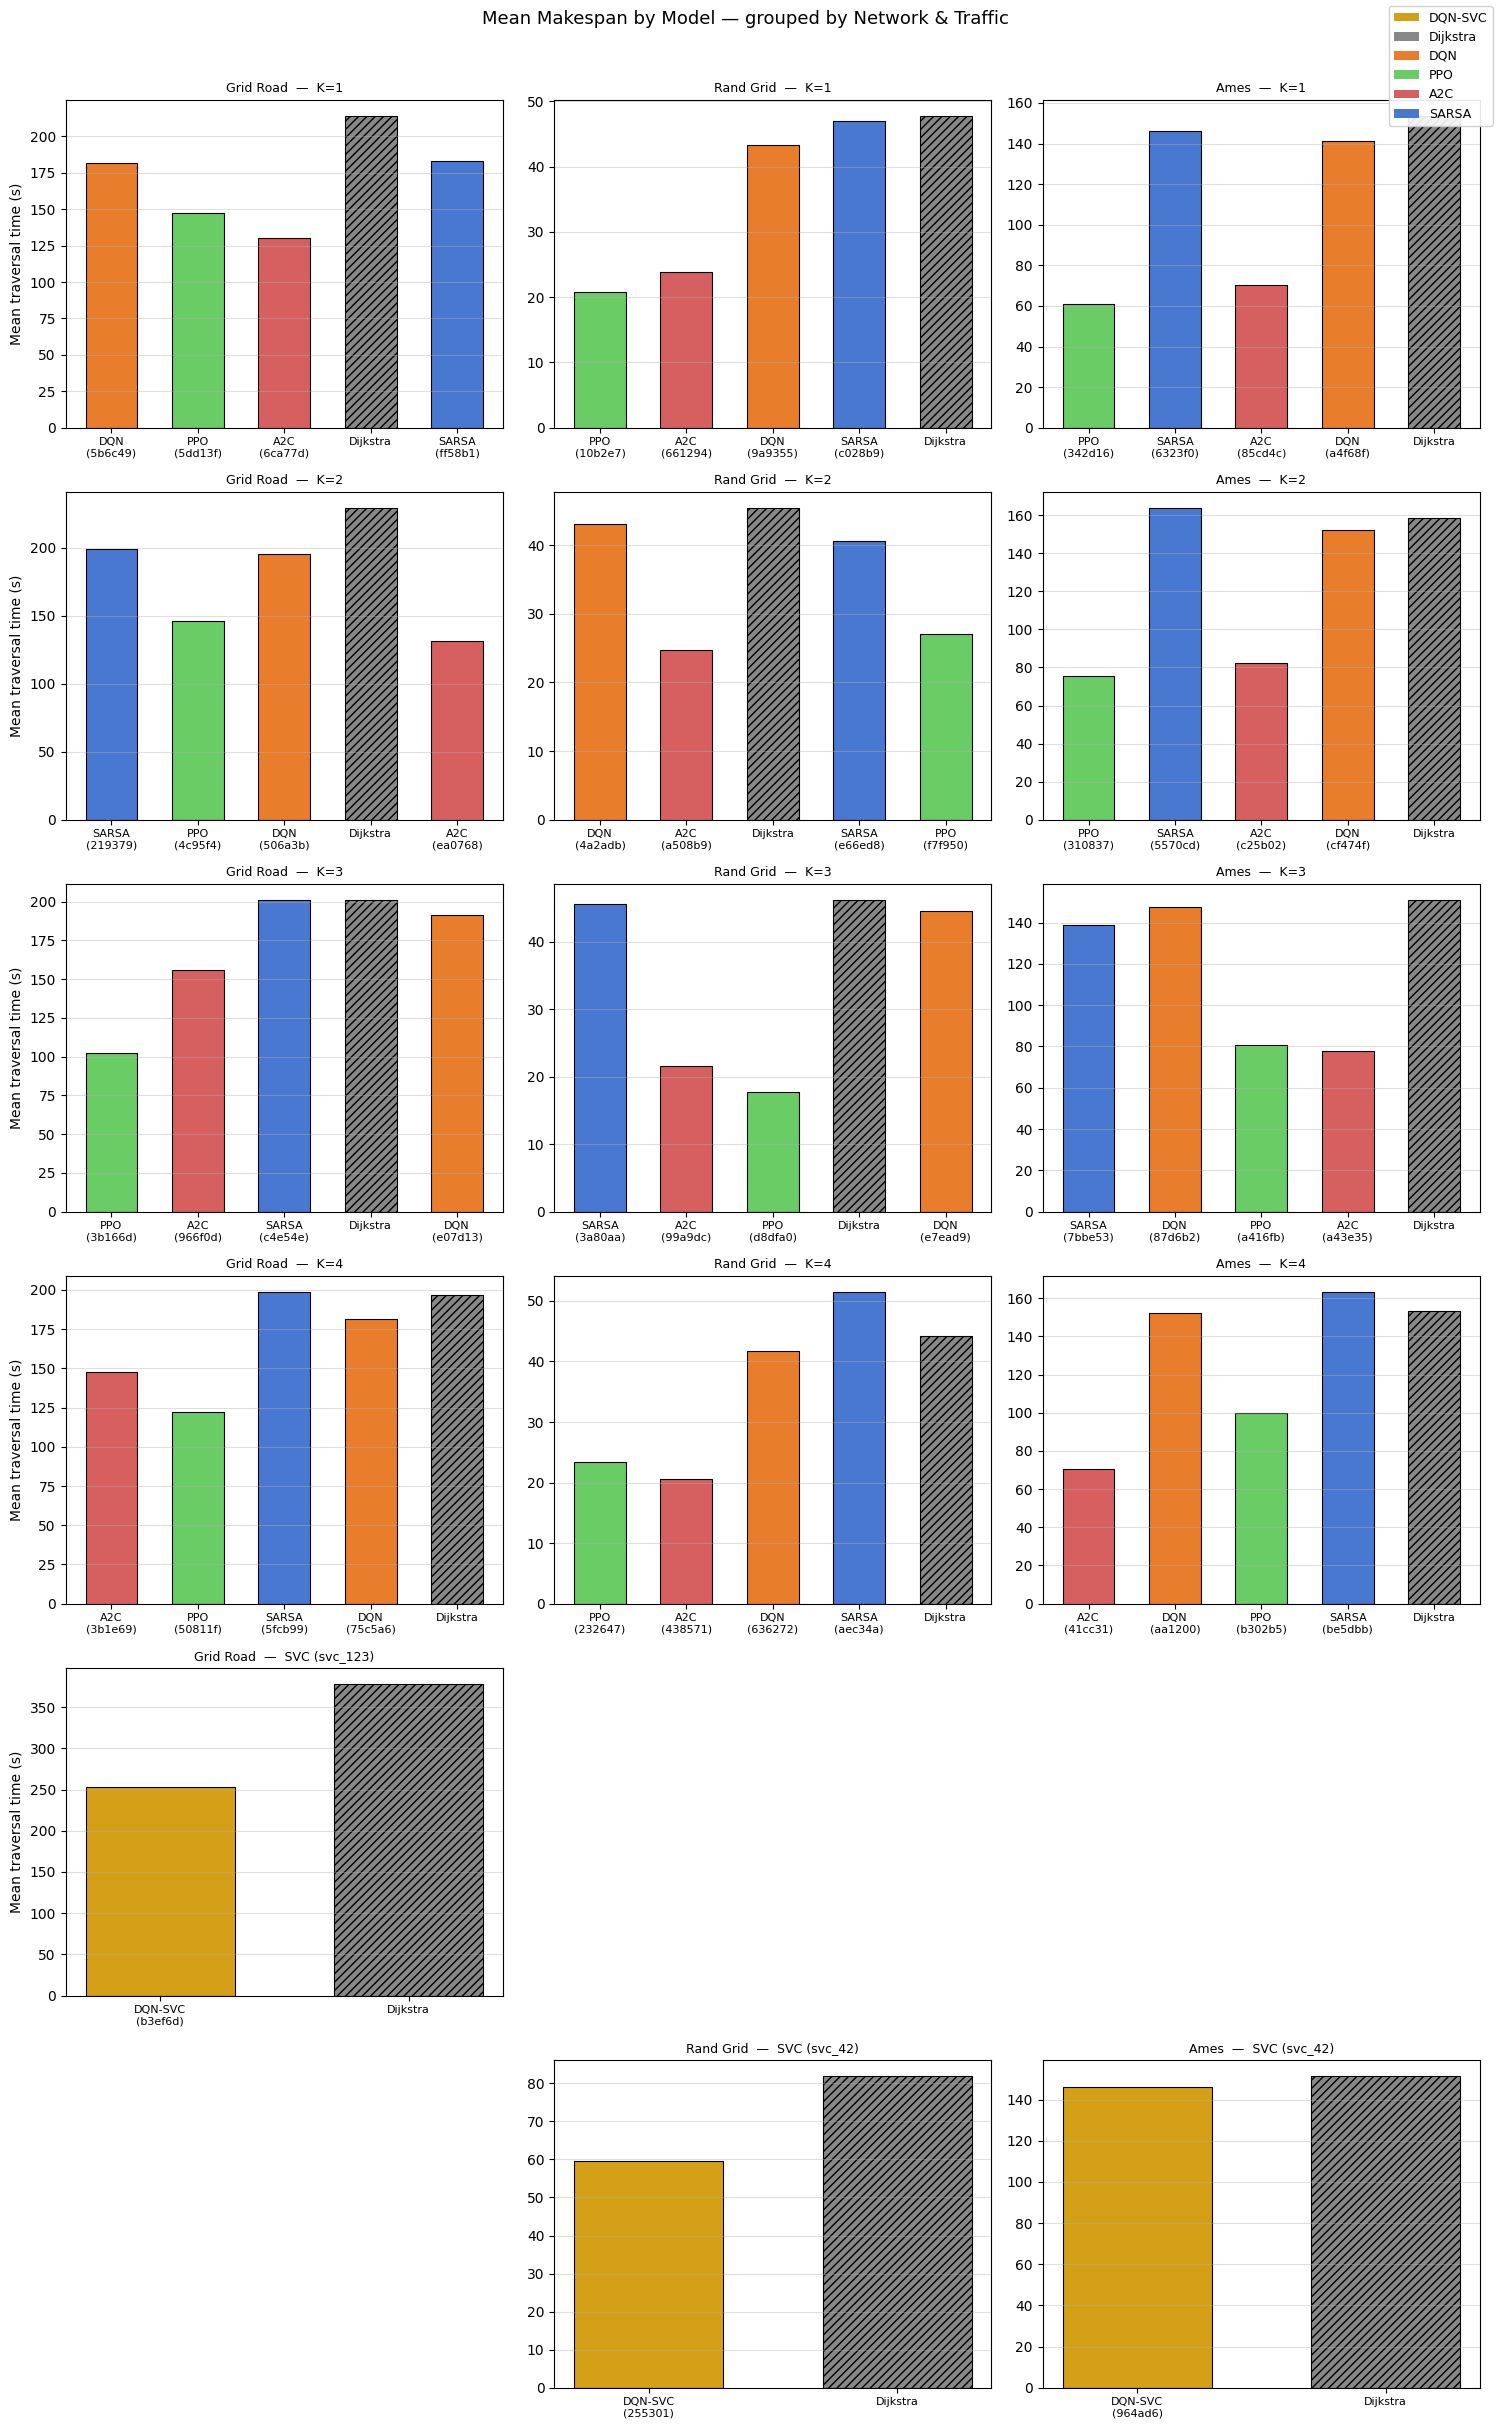

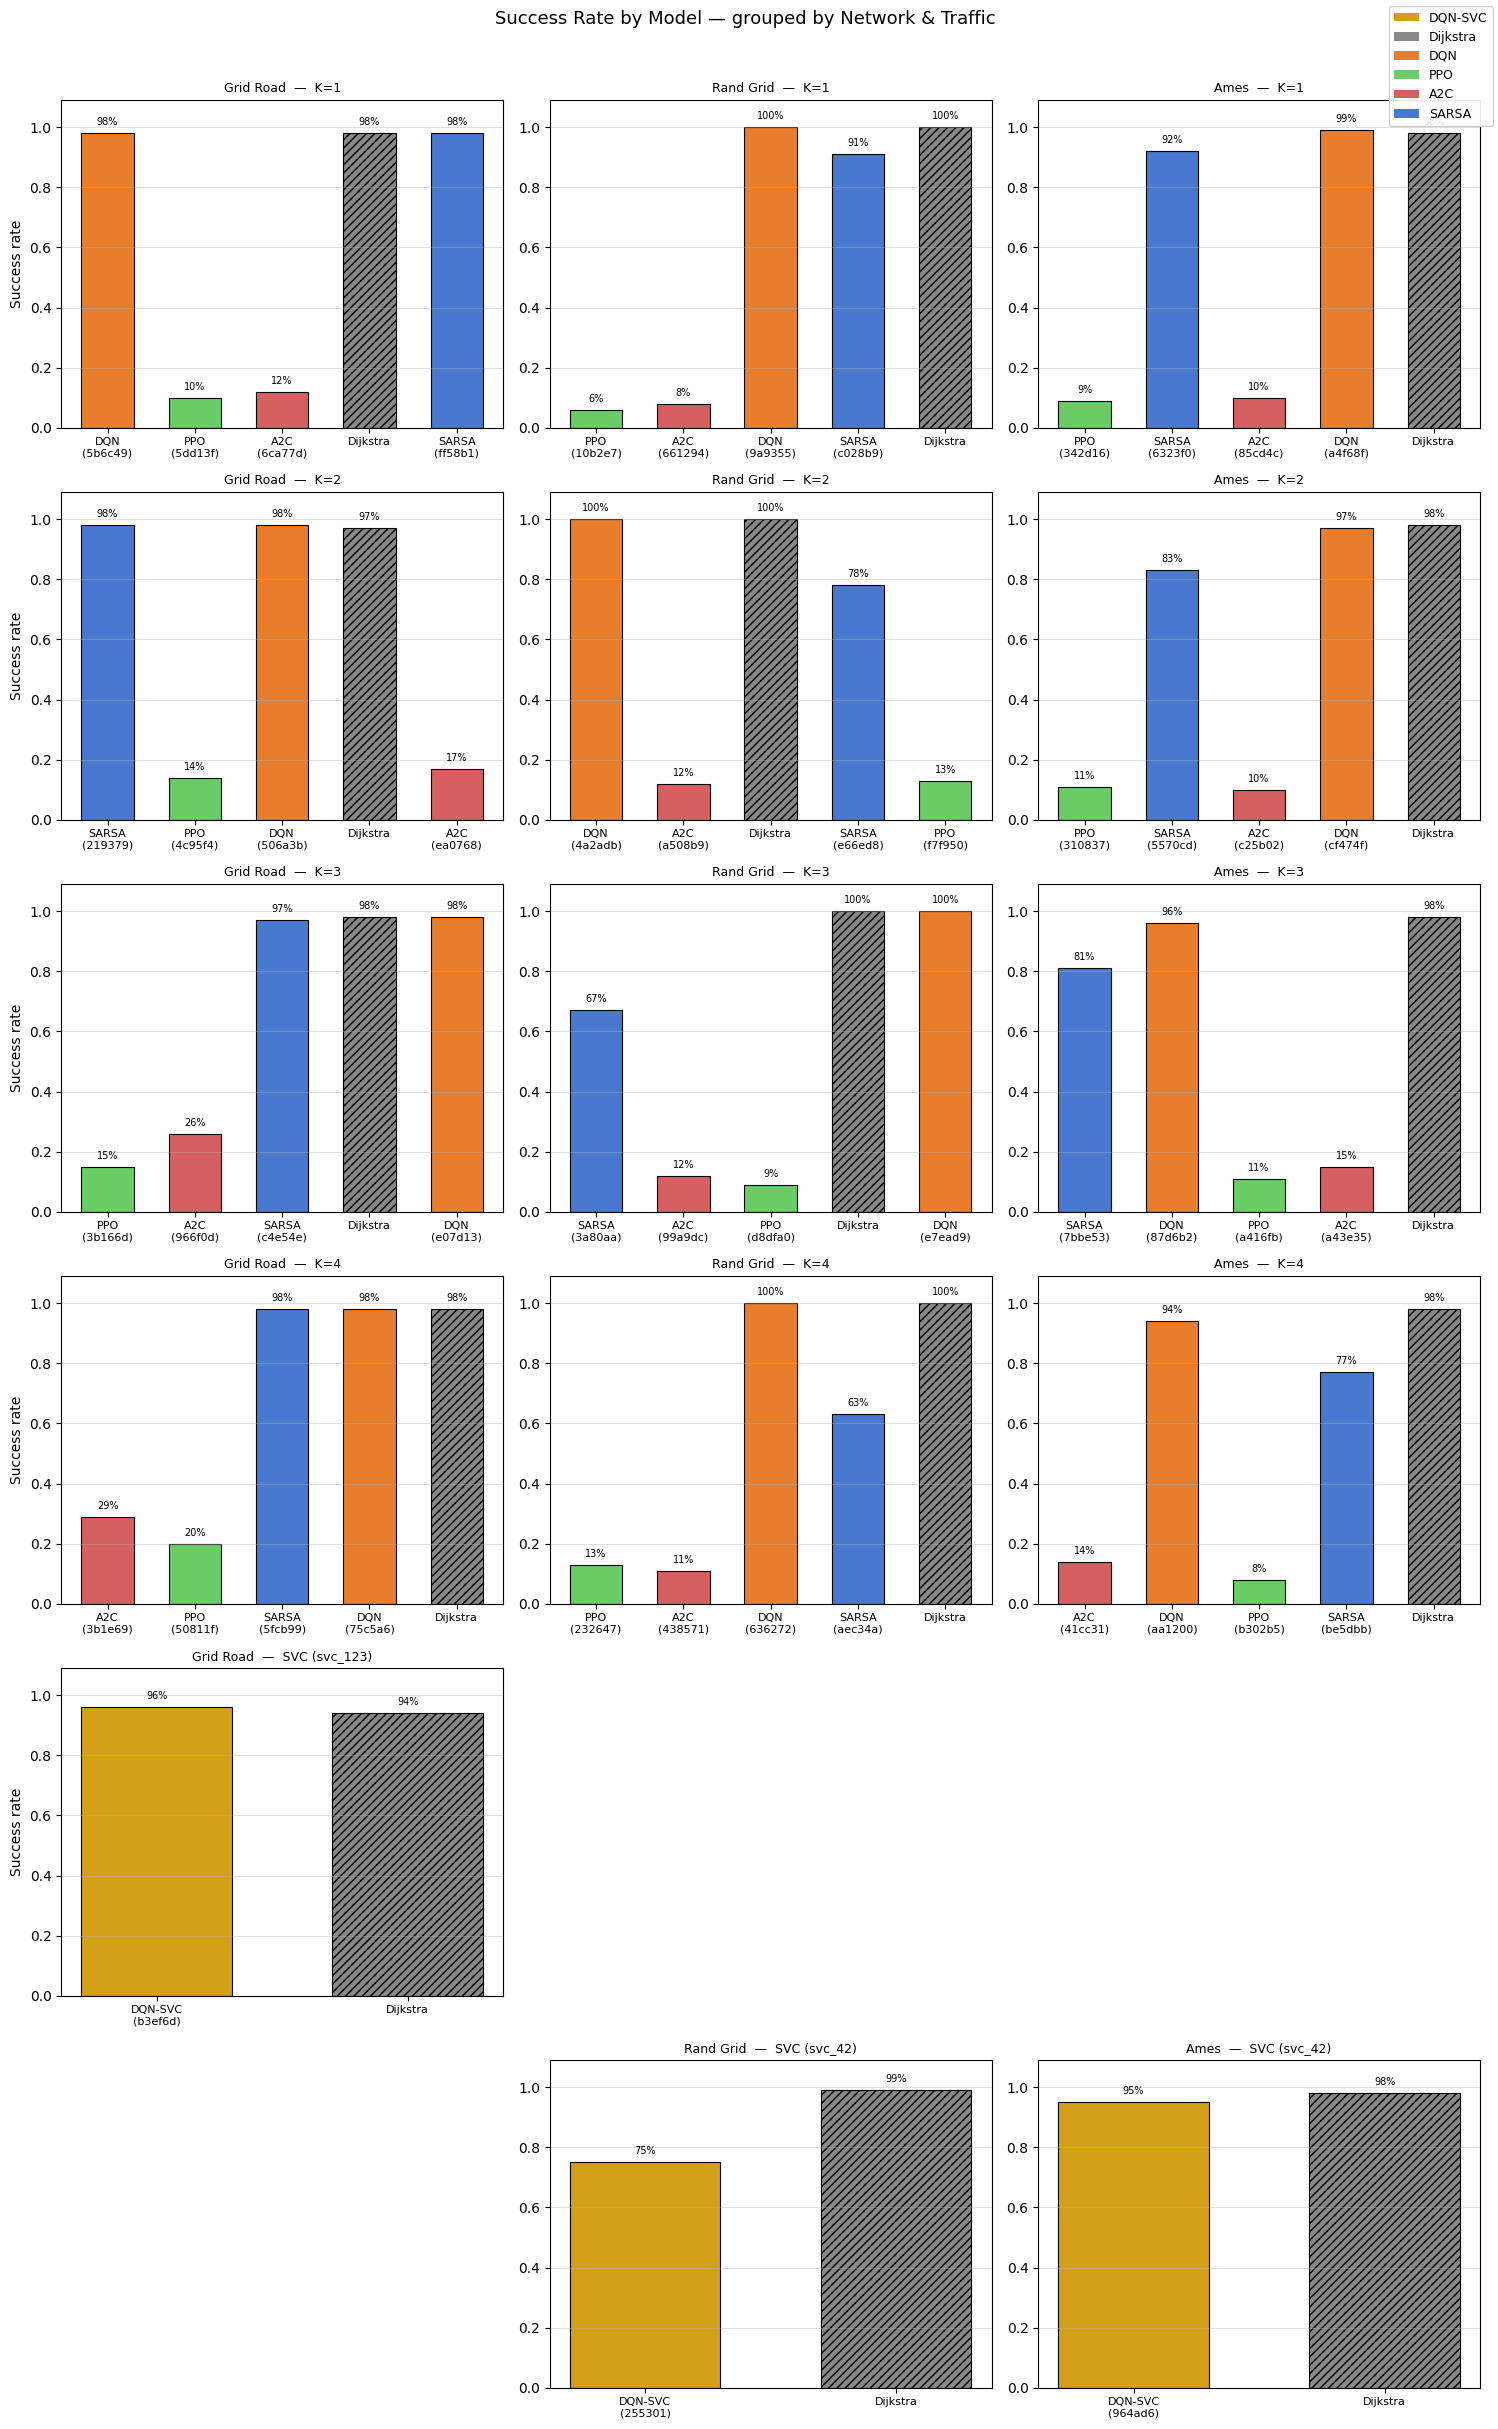

In [49]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

model_algo = {model: algo for (_, _, model), (_, _, algo) in best.items()}

ALGO_COLORS = {
    'dijkstra': '#888888', 'sarsa': '#4878cf', 'dqn': '#e87d2b',
    'dqn_svc': '#d4a017', 'ppo': '#6acc65', 'a2c': '#d65f5f',
}
ALGO_LABELS = {
    'dijkstra': 'Dijkstra', 'sarsa': 'SARSA', 'dqn': 'DQN',
    'dqn_svc': 'DQN-SVC', 'ppo': 'PPO', 'a2c': 'A2C',
}
NET_LABELS  = {'N1': 'Grid Road', 'N2': 'Rand Grid', 'N3': 'Ames'}

# Build traffic labels dynamically from whatever traffic IDs appear in results
def _make_traf_label(tid):
    if tid.startswith('SVC-'):
        tag = tid[4:]   # e.g. "svc_123"
        return f'SVC ({tag})'
    return {'T1': 'K=1', 'T2': 'K=2', 'T3': 'K=3', 'T4': 'K=4'}.get(tid, tid)

NETWORKS = ['N1', 'N2', 'N3']
TRAFFICS = sorted(results_df['traffic'].unique(), key=lambda t: (not t.startswith('T'), t))

def model_display(model):
    algo  = model_algo.get(model, model)
    label = ALGO_LABELS.get(algo, algo.upper())
    if model != 'dijkstra':
        label += f'\n({model[:6]})'
    return label

for metric, ylabel, title_prefix in [
    ('makespan_mean', 'Mean traversal time (s)', 'Mean Makespan'),
    ('success_rate',  'Success rate',            'Success Rate'),
]:
    present_networks = [n for n in NETWORKS if n in results_df['network'].values]
    n_rows = len(TRAFFICS)
    n_cols = len(present_networks)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), sharey=False)
    if n_rows == 1:
        axes = axes[np.newaxis, :]
    if n_cols == 1:
        axes = axes[:, np.newaxis]
    fig.suptitle(f'{title_prefix} by Model — grouped by Network & Traffic',
                 fontsize=13, y=1.01)

    for row_i, tid in enumerate(TRAFFICS):
        for col_i, nid in enumerate(present_networks):
            ax = axes[row_i][col_i]
            subset = results_df[
                (results_df['network'] == nid) & (results_df['traffic'] == tid)
            ].reset_index(drop=True)

            if subset.empty:
                ax.set_visible(False)
                continue

            models  = subset['model'].tolist()
            values  = subset[metric].tolist()
            labels  = [model_display(m) for m in models]
            colors  = [ALGO_COLORS.get(model_algo.get(m, ''), '#aaaaaa') for m in models]
            hatches = ['////' if m == 'dijkstra' else '' for m in models]

            bars = ax.bar(range(len(models)), values, color=colors,
                          width=0.6, edgecolor='black', linewidth=0.8)
            for bar, hatch in zip(bars, hatches):
                bar.set_hatch(hatch)

            ax.set_xticks(range(len(models)))
            ax.set_xticklabels(labels, fontsize=8)
            ax.set_title(f'{NET_LABELS.get(nid, nid)}  —  {_make_traf_label(tid)}', fontsize=9)
            ax.set_ylabel(ylabel if col_i == 0 else '')
            ax.grid(axis='y', alpha=0.4)
            if metric == 'success_rate':
                ax.set_ylim(0, 1.09)
                for i, v in enumerate(values):
                    ax.text(i, v + 0.02, f'{v:.0%}', ha='center', va='bottom', fontsize=7)

    all_algos = list(dict.fromkeys(
        model_algo.get(m, m) for m in results_df['model'].unique()
    ))
    legend_patches = [
        mpatches.Patch(facecolor=ALGO_COLORS.get(a, '#aaaaaa'),
                       label=ALGO_LABELS.get(a, a.upper()))
        for a in all_algos
    ]
    fig.legend(handles=legend_patches, loc='upper right', fontsize=9, framealpha=0.9)
    plt.tight_layout()
    plt.show()